In [ ]:
!pip install --extra-index-url=https://pypi.nvidia.com cudf-cu12

Looking in indexes: https://pypi.org/simple, https://pypi.nvidia.com


In [ ]:
import os
from google.colab import drive
import polars as pl
import pyarrow.parquet as pq
%load_ext cudf.pandas

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import cudf
print("cuDF Pandas GPU mode is active!")

cuDF Pandas GPU mode is active!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Shape: (20000, 11)


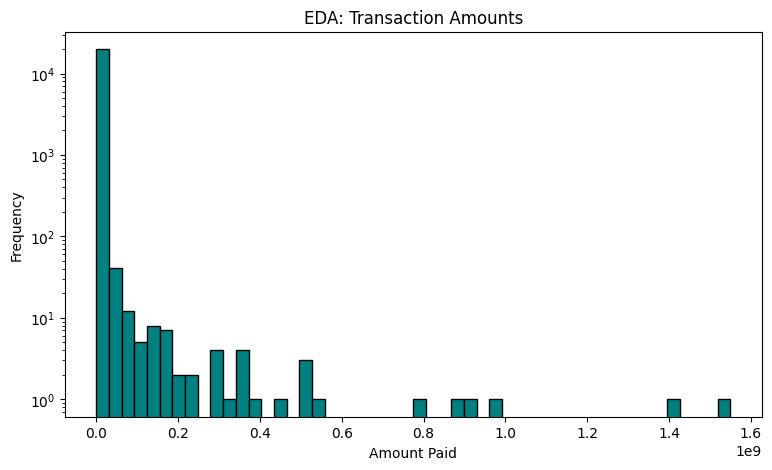

In [ ]:
trans_path = "./Data/raw/HI-Large_Trans.parquet"

df = pl.read_parquet(trans_path, n_rows=20000)

print("Shape:", df.shape)

amounts = df.select("Amount Paid").drop_nulls().to_numpy().flatten()

plt.figure(figsize=(9, 5))
plt.hist(amounts, bins=50, color='#008080', edgecolor='black', log=True)
plt.title("EDA: Transaction Amounts")
plt.xlabel("Amount Paid")
plt.ylabel("Frequency")
plt.show()


In [ ]:
# Set working directory to the repository folder
os.chdir('/content/drive/MyDrive/AML_Project/aml-compliance-system-main')

# Display current directory contents
print("Current Directory:", os.getcwd())
print("Contents:", os.listdir('.'))

Current Directory: /content/drive/MyDrive/AML_Project/aml-compliance-system-main
Contents: ['docker-compose.yml', 'notebooks', 'src', 'tests', 'README.md', 'digram.jfif', '.env', 'requirements.txt', 'Data', 'aml-compliance-system-main']


In [ ]:
raw_data_path = './Data/raw'
print("Raw Data Files:", os.listdir(raw_data_path))

Raw Data Files: ['HI-Large_Trans.csv', 'HI-Large_Patterns.txt', 'HI-Large_accounts.csv', 'HI-Large_Trans.parquet', 'HI-Large_Merged.parquet']


In [ ]:
# Stream the massive 17 GB CSV straight into compressed Parquet on disk
# This uses zero RAM and bypasses CPU/GPU memory limits completely
  # pl.scan_csv('./Data/raw/HI-Large_Trans.csv').sink_parquet('./Data/raw/HI-Large_Trans.parquet')

  # print("Conversion complete! Parquet file saved.")

In [ ]:
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(200)

polars.config.Config

In [ ]:
# 1. Optimally executed preview on GPU
query = (
    pl.scan_parquet('./Data/raw/HI-Large_Trans.parquet')
    .filter(pl.col("Is Laundering") == 1)
    .head(10)  # Limits memory usage to 10 rows
)

result = query.collect(engine="gpu")


print(result)

shape: (10, 11)
┌──────────────────┬───────────┬───────────┬─────────┬──────────────────────┬─────────────────┬────────────────────┬─────────────┬──────────────────┬────────────────┬───────────────┐
│ Timestamp        ┆ From Bank ┆ Account   ┆ To Bank ┆ Account_duplicated_0 ┆ Amount Received ┆ Receiving Currency ┆ Amount Paid ┆ Payment Currency ┆ Payment Format ┆ Is Laundering │
│ ---              ┆ ---       ┆ ---       ┆ ---     ┆ ---                  ┆ ---             ┆ ---                ┆ ---         ┆ ---              ┆ ---            ┆ ---           │
│ str              ┆ i64       ┆ str       ┆ i64     ┆ str                  ┆ f64             ┆ str                ┆ f64         ┆ str              ┆ str            ┆ i64           │
╞══════════════════╪═══════════╪═══════════╪═════════╪══════════════════════╪═════════════════╪════════════════════╪═════════════╪══════════════════╪════════════════╪═══════════════╡
│ 2022/08/01 00:19 ┆ 70        ┆ 100428660 ┆ 8381    ┆ 8035B3E00     

In [ ]:
# 1. Check Patterns file schema/columns
print("--- Patterns Columns ---")
patterns_preview = pl.read_csv('./Data/raw/HI-Large_Patterns.txt', separator='\t', n_rows=5)
print(patterns_preview.columns)

# './Data/raw/HI-Large_Patterns.txt'
# 2. Check Accounts file schema/columns
print("\n--- Accounts Columns ---")
accounts_preview = pl.read_csv('./Data/raw/HI-Large_accounts.csv', n_rows=5)
print(accounts_preview.columns)

# 3. Check Transactions schema/columns
print("\n--- Transactions Columns ---")
trans_preview = pl.read_parquet('./Data/raw/HI-Large_Trans.parquet', n_rows=5)
print(trans_preview.columns)

--- Patterns Columns ---
['BEGIN LAUNDERING ATTEMPT - STACK']

--- Accounts Columns ---
['Bank Name', 'Bank ID', 'Account Number', 'Entity ID', 'Entity Name']

--- Transactions Columns ---
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account_duplicated_0', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


In [ ]:
with open('./Data/raw/HI-Large_Patterns.txt', 'r', encoding='utf-8') as f:
    for i in range(20):
        print(f.readline().strip())

BEGIN LAUNDERING ATTEMPT - STACK
2022/08/09 05:14,00952,8139F54E0,0111632,8062C56E0,5331.44,US Dollar,5331.44,US Dollar,ACH,1
2022/08/13 13:09,0111632,8062C56E0,008456,81363F620,5602.59,US Dollar,5602.59,US Dollar,ACH,1
2022/08/15 07:40,0118693,823D5EB90,013729,801CF2E60,1400.54,US Dollar,1400.54,US Dollar,ACH,1
2022/08/15 14:19,013729,801CF2E60,0123621,81A7090F0,1467.94,US Dollar,1467.94,US Dollar,ACH,1
2022/08/13 12:40,0024750,81363F410,0213834,808757B00,16898.29,US Dollar,16898.29,US Dollar,ACH,1
2022/08/22 06:34,0213834,808757B00,000,800073EF0,17607.19,US Dollar,17607.19,US Dollar,ACH,1
END LAUNDERING ATTEMPT - STACK

BEGIN LAUNDERING ATTEMPT - CYCLE:  Max 12 hops
2022/08/01 00:19,0134266,814167590,0036925,810E343A0,132713.46,Yuan,132713.46,Yuan,ACH,1
2022/08/01 13:05,0036925,810E343A0,0119211,814AB4F60,18264.20,US Dollar,18264.20,US Dollar,ACH,1
2022/08/03 13:28,0119211,814AB4F60,0132965,81B88A230,14567.69,Euro,14567.69,Euro,ACH,1
2022/08/09 02:32,0132965,81B88A230,0137089,810C719

In [ ]:
# 1. DEFINE FILE PATHS
trans_path = (
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/raw/HI-Large_Trans.parquet"
)

accounts_path = (
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/raw/HI-Large_accounts.csv"
)

patterns_path = (
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/raw/HI-Large_Patterns.txt"
)

merged_path = (
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/raw/HI-Large_Merged.parquet"
)

# 2. LOAD TRANSACTION AND ACCOUNT DATA USING LAZY SCANS
# Load the transactions dataset lazily to avoid loading
# the entire dataset into memory.
trans_lazy = pl.scan_parquet(trans_path)

# Load the account metadata lazily.
accounts_lazy = pl.scan_csv(accounts_path)



In [ ]:
# 3. PREPARE SENDER ACCOUNT METADATA

# Select and rename account information for the sender.
from_accounts = accounts_lazy.select([
    pl.col("Account Number").alias("Account"),
    pl.col("Entity ID").alias("From_Entity_ID"),
    pl.col("Entity Name").alias("From_Entity_Name"),
    pl.col("Bank ID").alias("From_Account_Bank_ID")
])


# 4. PREPARE RECEIVER ACCOUNT METADATA


# Select and rename account information for the receiver.
to_accounts = accounts_lazy.select([
    pl.col("Account Number").alias("Account_duplicated_0"),
    pl.col("Entity ID").alias("To_Entity_ID"),
    pl.col("Entity Name").alias("To_Entity_Name"),
    pl.col("Bank ID").alias("To_Account_Bank_ID")
])



In [ ]:
# 5. MERGE TRANSACTIONS WITH ACCOUNT METADATA

# Add sender and receiver account information to each transaction.
merged_lazy = (
    trans_lazy
    .join(
        from_accounts,
        on="Account",
        how="left"
    )
    .join(
        to_accounts,
        on="Account_duplicated_0",
        how="left"
    )
)


# 6. EXTRACT TRANSACTIONS FROM THE PATTERNS FILE


# Create a list to store extracted pattern transactions.
records = []

# Store the currently active laundering pattern.
current_pattern = None


# Read the patterns file line by line.
with open(patterns_path, "r", encoding="utf-8") as f:

    for line in f:

        # Remove leading/trailing whitespace and line breaks.
        line = line.strip()

        # Detect the beginning of a laundering pattern.
        if line.startswith("BEGIN LAUNDERING ATTEMPT"):

            # Extract the laundering pattern type.
            current_pattern = (
                line
                .replace("BEGIN LAUNDERING ATTEMPT - ", "")
                .split(":")[0]
                .strip()
            )

        # Detect the end of the current laundering pattern.
        elif line.startswith("END LAUNDERING ATTEMPT"):

            current_pattern = None

        # Extract transaction records while a pattern is active.
        elif line and current_pattern:

            # Split transaction values using commas.
            values = line.split(",")

            # Only process valid transaction records containing
            # exactly 11 transaction fields.
            if len(values) == 11:

                # Append the corresponding pattern type.
                records.append(values + [current_pattern])

In [ ]:
# 7. CREATE THE PATTERNS DATAFRAME
patterns_df = pl.DataFrame(
    records,
    schema=[
        "Timestamp",
        "From Bank",
        "Account",
        "To Bank",
        "Account_duplicated_0",
        "Amount Received",
        "Receiving Currency",
        "Amount Paid",
        "Payment Currency",
        "Payment Format",
        "Is Laundering",
        "Pattern Type"
    ]
)

# 8. CONVERT PATTERN COLUMNS TO MATCH TRANSACTION DATA TYPES

# Define the transaction columns used to match patterns.
pattern_keys = [
    "Timestamp",
    "From Bank",
    "Account",
    "To Bank",
    "Account_duplicated_0",
    "Amount Received",
    "Receiving Currency",
    "Amount Paid",
    "Payment Currency",
    "Payment Format"
]


# Convert pattern columns to the same data types and formats
# used in the transactions dataset.
patterns_ready = (
    patterns_df
    .select(pattern_keys + ["Pattern Type"])
    .with_columns([

        # Match the transaction timestamp format.
        pl.col("Timestamp")
        .str.strptime(
            pl.Datetime,
            "%Y/%m/%d %H:%M",
            strict=False
        )
        .dt.strftime("%Y/%m/%d %H:%M")
        .alias("Timestamp"),

        # Match bank ID data types.
        pl.col("From Bank")
        .cast(pl.Int64, strict=False),

        pl.col("To Bank")
        .cast(pl.Int64, strict=False),

        # Match account data types.
        pl.col("Account")
        .cast(pl.String),

        pl.col("Account_duplicated_0")
        .cast(pl.String),

        # Match transaction amount data types.
        pl.col("Amount Received")
        .cast(pl.Float64, strict=False),

        pl.col("Amount Paid")
        .cast(pl.Float64, strict=False),

        # Ensure categorical columns are strings.
        pl.col("Receiving Currency")
        .cast(pl.String),

        pl.col("Payment Currency")
        .cast(pl.String),

        pl.col("Payment Format")
        .cast(pl.String),

        # Ensure pattern labels are stored as strings.
        pl.col("Pattern Type")
        .cast(pl.String)
    ])

    # Remove duplicate transaction keys to prevent row multiplication
    # during the join operation.
    .unique(subset=pattern_keys)

    # Convert to LazyFrame for efficient processing.
    .lazy()
)

/tmp/ipykernel_1447/122195793.py:2: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  patterns_df = pl.DataFrame(


In [ ]:
# 9. ADD PATTERN INFORMATION TO THE MERGED DATASET


# Use a left join to preserve all original transactions.
# Transactions that exist in the Patterns file will receive
# their corresponding Pattern Type.
final_lazy = (
    merged_lazy
    .join(
        patterns_ready,
        on=pattern_keys,
        how="left"
    )
)

# 10. SAVE THE FINAL UNIFIED DATASET


# Write the complete dataset to a single Parquet file.
final_lazy.sink_parquet(
    merged_path,
    compression="zstd"
)


print("================================================")
print("SUCCESS: DATA MERGING COMPLETED")
print("================================================")
print("The final dataset includes:")
print("1. Transaction data")
print("2. Sender account metadata")
print("3. Receiver account metadata")
print("4. Laundering pattern information")
print("================================================")
print(f"Saved file: {merged_path}")

SUCCESS: DATA MERGING COMPLETED
The final dataset includes:
1. Transaction data
2. Sender account metadata
3. Receiver account metadata
4. Laundering pattern information
Saved file: /content/drive/MyDrive/AML_Project/aml-compliance-system-main/Data/raw/HI-Large_Merged.parquet


In [ ]:
final_check = pl.scan_parquet(
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/raw/HI-Large_Merged.parquet"
)

# Check the total number of transactions and pattern matches.
validation = (
    final_check
    .select([
        pl.len().alias("Total Transactions"),

        pl.col("Pattern Type")
        .is_not_null()
        .sum()
        .alias("Transactions with Pattern"),

        pl.col("Pattern Type")
        .is_null()
        .sum()
        .alias("Transactions without Pattern")
    ])
    .collect()
)

print(validation)

shape: (1, 3)
┌────────────────────┬───────────────────────────┬──────────────────────────────┐
│ Total Transactions ┆ Transactions with Pattern ┆ Transactions without Pattern │
│ ---                ┆ ---                       ┆ ---                          │
│ u32                ┆ u32                       ┆ u32                          │
╞════════════════════╪═══════════════════════════╪══════════════════════════════╡
│ 181294816          ┆ 138362                    ┆ 181156454                    │
└────────────────────┴───────────────────────────┴──────────────────────────────┘


In [ ]:
pattern_distribution = (
    final_check
    .filter(pl.col("Pattern Type").is_not_null())
    .group_by("Pattern Type")
    .agg(
        pl.len().alias("Transaction Count")
    )
    .sort("Transaction Count", descending=True)
    .collect()
)

print(pattern_distribution)

shape: (8, 2)
┌────────────────┬───────────────────┐
│ Pattern Type   ┆ Transaction Count │
│ ---            ┆ ---               │
│ str            ┆ u32               │
╞════════════════╪═══════════════════╡
│ SCATTER-GATHER ┆ 27068             │
│ GATHER-SCATTER ┆ 26429             │
│ STACK          ┆ 23710             │
│ FAN-OUT        ┆ 13600             │
│ FAN-IN         ┆ 13323             │
│ CYCLE          ┆ 12378             │
│ BIPARTITE      ┆ 12213             │
│ RANDOM         ┆ 9641              │
└────────────────┴───────────────────┘


In [ ]:
merged_path = (
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/raw/HI-Large_Merged.parquet"
)

# Check if the file exists.
if os.path.exists(merged_path):

    # Get the file size in GB.
    file_size_gb = os.path.getsize(merged_path) / (1024 ** 3)

    print(f"File exists: Yes")
    print(f"File size: {file_size_gb:.2f} GB")

else:
    print("File does not exist.")

File exists: Yes
File size: 6.84 GB


#  Start The data cleaning

---

In [ ]:
# Define the path of the merged dataset.
merged_path = (
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/raw/HI-Large_Merged.parquet"
)

# Load the dataset lazily to avoid loading the entire
# dataset into RAM.
df_lazy = pl.scan_parquet(merged_path)

print("Dataset loaded successfully using LazyFrame.")

Dataset loaded successfully using LazyFrame.


In [ ]:
# Display the schema of the merged dataset.
schema = df_lazy.collect_schema()

print("DATASET SCHEMA")

for column, dtype in schema.items():
    print(f"{column}: {dtype}")

DATASET SCHEMA
Timestamp: String
From Bank: Int64
Account: String
To Bank: Int64
Account_duplicated_0: String
Amount Received: Float64
Receiving Currency: String
Amount Paid: Float64
Payment Currency: String
Payment Format: String
Is Laundering: Int64
From_Entity_ID: String
From_Entity_Name: String
From_Account_Bank_ID: Int64
To_Entity_ID: String
To_Entity_Name: String
To_Account_Bank_ID: Int64
Pattern Type: String


In [ ]:
# STEP 3: CHECK MISSING VALUES

# Get all column names.
columns = list(schema.keys())

# Calculate the number of missing values in every column.
missing_values = (
    df_lazy
    .select([
        pl.col(column)
        .is_null()
        .sum()
        .alias(column)
        for column in columns
    ])
    .collect()
)

print("================================================")
print("MISSING VALUES PER COLUMN")
print("================================================")

print(missing_values)

MISSING VALUES PER COLUMN
shape: (1, 18)
┌───────────┬───────────┬─────────┬─────────┬───┬────────────┬────────────┬────────────┬───────────┐
│ Timestamp ┆ From Bank ┆ Account ┆ To Bank ┆ … ┆ To_Entity_ ┆ To_Entity_ ┆ To_Account ┆ Pattern   │
│ ---       ┆ ---       ┆ ---     ┆ ---     ┆   ┆ ID         ┆ Name       ┆ _Bank_ID   ┆ Type      │
│ u32       ┆ u32       ┆ u32     ┆ u32     ┆   ┆ ---        ┆ ---        ┆ ---        ┆ ---       │
│           ┆           ┆         ┆         ┆   ┆ u32        ┆ u32        ┆ u32        ┆ u32       │
╞═══════════╪═══════════╪═════════╪═════════╪═══╪════════════╪════════════╪════════════╪═══════════╡
│ 0         ┆ 0         ┆ 0       ┆ 0       ┆ … ┆ 0          ┆ 0          ┆ 0          ┆ 181156454 │
└───────────┴───────────┴─────────┴─────────┴───┴────────────┴────────────┴────────────┴───────────┘


In [ ]:
# STEP 4: HANDLE MISSING VALUES IN PATTERN TYPE

# Replace missing Pattern Type values with NO_PATTERN.
# Missing values are expected because most transactions
# are not associated with a known laundering pattern.

df_cleaning = (
    df_lazy
    .with_columns(

        pl.col("Pattern Type")
        .fill_null("NO_PATTERN")
        .alias("Pattern Type")

    )
)

print("Pattern Type missing values replaced successfully.")

Pattern Type missing values replaced successfully.


In [ ]:
# STEP 5: CHECK PATTERN DISTRIBUTION

pattern_distribution = (
    df_cleaning
    .group_by("Pattern Type")
    .agg(

        # Count transactions for each pattern type.
        pl.len().alias("Transaction Count")

    )
    .sort(
        "Transaction Count",
        descending=True
    )
    .collect()
)

print("=" * 60)
print("PATTERN TYPE DISTRIBUTION")
print("=" * 60)

print(pattern_distribution)

PATTERN TYPE DISTRIBUTION
shape: (9, 2)
┌────────────────┬───────────────────┐
│ Pattern Type   ┆ Transaction Count │
│ ---            ┆ ---               │
│ str            ┆ u32               │
╞════════════════╪═══════════════════╡
│ NO_PATTERN     ┆ 181156454         │
│ SCATTER-GATHER ┆ 27068             │
│ GATHER-SCATTER ┆ 26429             │
│ STACK          ┆ 23710             │
│ FAN-OUT        ┆ 13600             │
│ FAN-IN         ┆ 13323             │
│ CYCLE          ┆ 12378             │
│ BIPARTITE      ┆ 12213             │
│ RANDOM         ┆ 9641              │
└────────────────┴───────────────────┘


In [ ]:

# STEP 6: CHECK TIMESTAMP FORMAT

# Display a sample of timestamp values to identify
# the exact date and time format used in the dataset.

timestamp_sample = (
    df_cleaning
    .select("Timestamp")
    .head(10)
    .collect()
)

print("=" * 60)
print("TIMESTAMP SAMPLE")
print("=" * 60)

print(timestamp_sample)

TIMESTAMP SAMPLE
shape: (10, 1)
┌──────────────────┐
│ Timestamp        │
│ ---              │
│ str              │
╞══════════════════╡
│ 2022/08/01 00:27 │
│ 2022/08/01 00:23 │
│ 2022/08/01 00:13 │
│ 2022/08/01 00:00 │
│ 2022/08/01 00:09 │
│ 2022/08/01 00:09 │
│ 2022/08/01 00:17 │
│ 2022/08/01 00:13 │
│ 2022/08/01 00:01 │
│ 2022/08/01 00:23 │
└──────────────────┘


In [ ]:
# STEP 6: CONVERT TIMESTAMP TO DATETIME

# Convert the Timestamp column from String to Datetime.
# The expected format is: YYYY/MM/DD HH:MM

df_cleaning = (
    df_cleaning
    .with_columns(

        pl.col("Timestamp")
        .str.strptime(
            pl.Datetime,
            format="%Y/%m/%d %H:%M",
            strict=False
        )
        .alias("Timestamp")

    )
)

print("Timestamp conversion step added successfully.")

Timestamp conversion step added successfully.


In [ ]:
# STEP 7: VALIDATE TIMESTAMP CONVERSION
timestamp_validation = (
    df_cleaning
    .select([

        # Count missing or invalid timestamps after conversion.
        pl.col("Timestamp")
        .is_null()
        .sum()
        .alias("Invalid Timestamps"),

        # Find the earliest transaction timestamp.
        pl.col("Timestamp")
        .min()
        .alias("Earliest Transaction"),

        # Find the latest transaction timestamp.
        pl.col("Timestamp")
        .max()
        .alias("Latest Transaction")

    ])
    .collect()
)

print("=" * 60)
print("TIMESTAMP VALIDATION")
print("=" * 60)

print(timestamp_validation)

TIMESTAMP VALIDATION
shape: (1, 3)
┌────────────────────┬──────────────────────┬─────────────────────┐
│ Invalid Timestamps ┆ Earliest Transaction ┆ Latest Transaction  │
│ ---                ┆ ---                  ┆ ---                 │
│ u32                ┆ datetime[μs]         ┆ datetime[μs]        │
╞════════════════════╪══════════════════════╪═════════════════════╡
│ 0                  ┆ 2022-08-01 00:00:00  ┆ 2023-01-12 16:49:00 │
└────────────────────┴──────────────────────┴─────────────────────┘


In [ ]:
# STEP 8: VALIDATE TRANSACTION AMOUNTS


amount_validation = (
    df_cleaning
    .select([

        # Count missing values in Amount Received.
        pl.col("Amount Received")
        .is_null()
        .sum()
        .alias("Missing Amount Received"),

        # Count missing values in Amount Paid.
        pl.col("Amount Paid")
        .is_null()
        .sum()
        .alias("Missing Amount Paid"),

        # Count negative Amount Received values.
        (
            pl.col("Amount Received") < 0
        )
        .sum()
        .alias("Negative Amount Received"),

        # Count negative Amount Paid values.
        (
            pl.col("Amount Paid") < 0
        )
        .sum()
        .alias("Negative Amount Paid"),

        # Count zero Amount Received values.
        (
            pl.col("Amount Received") == 0
        )
        .sum()
        .alias("Zero Amount Received"),

        # Count zero Amount Paid values.
        (
            pl.col("Amount Paid") == 0
        )
        .sum()
        .alias("Zero Amount Paid"),

        # Get minimum and maximum Amount Received.
        pl.col("Amount Received")
        .min()
        .alias("Min Amount Received"),

        pl.col("Amount Received")
        .max()
        .alias("Max Amount Received"),

        # Get minimum and maximum Amount Paid.
        pl.col("Amount Paid")
        .min()
        .alias("Min Amount Paid"),

        pl.col("Amount Paid")
        .max()
        .alias("Max Amount Paid")

    ])
    .collect()
)

print("=" * 60)
print("TRANSACTION AMOUNT VALIDATION")
print("=" * 60)

print(amount_validation)

TRANSACTION AMOUNT VALIDATION
shape: (1, 10)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ Missing   ┆ Missing   ┆ Negative  ┆ Negative  ┆ … ┆ Min       ┆ Max       ┆ Min       ┆ Max      │
│ Amount    ┆ Amount    ┆ Amount    ┆ Amount    ┆   ┆ Amount    ┆ Amount    ┆ Amount    ┆ Amount   │
│ Received  ┆ Paid      ┆ Received  ┆ Paid      ┆   ┆ Received  ┆ Received  ┆ Paid      ┆ Paid     │
│ ---       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---      │
│ u32       ┆ u32       ┆ u32       ┆ u32       ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64      │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 0         ┆ 0         ┆ 0         ┆ 0         ┆ … ┆ 0.000001  ┆ 8.1586e12 ┆ 0.000001  ┆ 8.1586e1 │
│           ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 2        │
└───────────┴───────────┴───────────┴─────────

In [ ]:
# STEP 9: CHECK ZERO TRANSACTION AMOUNTS

zero_amounts = (
    df_cleaning
    .select([

        # Count transactions where Amount Received is zero.
        (pl.col("Amount Received") == 0)
        .sum()
        .alias("Zero Amount Received"),

        # Count transactions where Amount Paid is zero.
        (pl.col("Amount Paid") == 0)
        .sum()
        .alias("Zero Amount Paid")

    ])
    .collect()
)

print("=" * 60)
print("ZERO AMOUNT VALIDATION")
print("=" * 60)

print(zero_amounts)

ZERO AMOUNT VALIDATION
shape: (1, 2)
┌──────────────────────┬──────────────────┐
│ Zero Amount Received ┆ Zero Amount Paid │
│ ---                  ┆ ---              │
│ u32                  ┆ u32              │
╞══════════════════════╪══════════════════╡
│ 0                    ┆ 0                │
└──────────────────────┴──────────────────┘


In [ ]:
# STEP 10: CHECK DUPLICATE TRANSACTIONS

# Define the core columns that identify a transaction.
transaction_columns = [
    "Timestamp",
    "From Bank",
    "Account",
    "To Bank",
    "Account_duplicated_0",
    "Amount Received",
    "Receiving Currency",
    "Amount Paid",
    "Payment Currency",
    "Payment Format"
]

# Count the total number of transactions.
total_transactions = (
    df_cleaning
    .select(pl.len().alias("Total Transactions"))
    .collect()
    .item()
)

# Count unique transactions based on the original
# transaction-level columns only.
unique_transactions = (
    df_cleaning
    .unique(subset=transaction_columns)
    .select(pl.len().alias("Unique Transactions"))
    .collect()
    .item()
)

# Calculate the number of duplicate transactions.
duplicate_transactions = (
    total_transactions - unique_transactions
)

print("=" * 60)
print("DUPLICATE TRANSACTION CHECK")
print("=" * 60)

print(f"Total Transactions: {total_transactions:,}")
print(f"Unique Transactions: {unique_transactions:,}")
print(f"Duplicate Transactions: {duplicate_transactions:,}")

DUPLICATE TRANSACTION CHECK
Total Transactions: 181,294,816
Unique Transactions: 179,702,079
Duplicate Transactions: 1,592,737


In [ ]:
# STEP 11: CREATE FINAL CLEANED DATASET

# Remove duplicate transactions based on the transaction
# columns already validated in the duplicate check.
cleaned_final_lazy = (
    df_cleaning
    .unique(
        subset=transaction_columns,
        keep="first",
        maintain_order=False
    )
)

print("Final cleaned dataset pipeline is ready.")

Final cleaned dataset pipeline is ready.


In [ ]:
# STEP 12: SAVE FINAL CLEANED DATASET

# Define the output path.
cleaned_path = (
    "/content/drive/MyDrive/AML_Project/"
    "aml-compliance-system-main/Data/processed/"
    "HI-Large_Cleaned.parquet"
)

# Create the output directory if it does not exist.
os.makedirs(
    os.path.dirname(cleaned_path),
    exist_ok=True
)

# Save the existing cleaned LazyFrame.
# No unique() operation is performed to avoid high RAM usage.
df_cleaning.sink_parquet(
    cleaned_path,
    compression="zstd"
)

print("=" * 60)
print("CLEANED DATASET SAVED SUCCESSFULLY")
print("=" * 60)
print(f"Saved to: {cleaned_path}")

CLEANED DATASET SAVED SUCCESSFULLY
Saved to: /content/drive/MyDrive/AML_Project/aml-compliance-system-main/Data/processed/HI-Large_Cleaned.parquet


In [ ]:
#FILE VALIDATION

validation_lazy = pl.scan_parquet(cleaned_path)

# Check that the file can be read and get the row count.
final_count = (
    validation_lazy
    .select(pl.len().alias("Total Transactions"))
    .collect()
)

print(final_count)

shape: (1, 1)
┌────────────────────┐
│ Total Transactions │
│ ---                │
│ u32                │
╞════════════════════╡
│ 181294816          │
└────────────────────┘


# EDA after cleaning

In [ ]:
# Load the cleaned dataset lazily.
cleaned_path = (
    "./Data/processed/"
    "HI-Large_Cleaned.parquet")
eda_lazy = pl.scan_parquet(cleaned_path)

print("EDA dataset loaded successfully.")

EDA dataset loaded successfully.


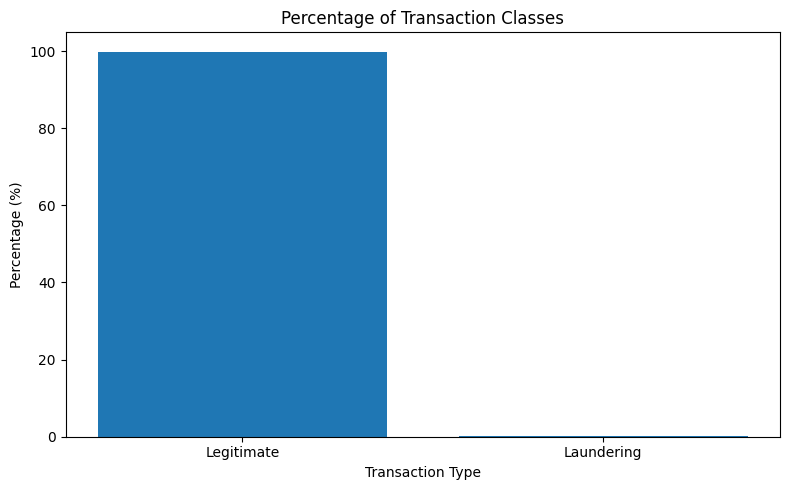

Legitimate: 99.8750%
Laundering: 0.1250%


In [ ]:
# GRAPH 2: LAUNDERING PERCENTAGE

total = sum(counts)

legitimate_percentage = counts[0] / total * 100
laundering_percentage = counts[1] / total * 100

plt.figure(figsize=(8, 5))

plt.bar(
    ["Legitimate", "Laundering"],
    [legitimate_percentage, laundering_percentage]
)

plt.title("Percentage of Transaction Classes")
plt.xlabel("Transaction Type")
plt.ylabel("Percentage (%)")

plt.tight_layout()
plt.show()

print(f"Legitimate: {legitimate_percentage:.4f}%")
print(f"Laundering: {laundering_percentage:.4f}%")

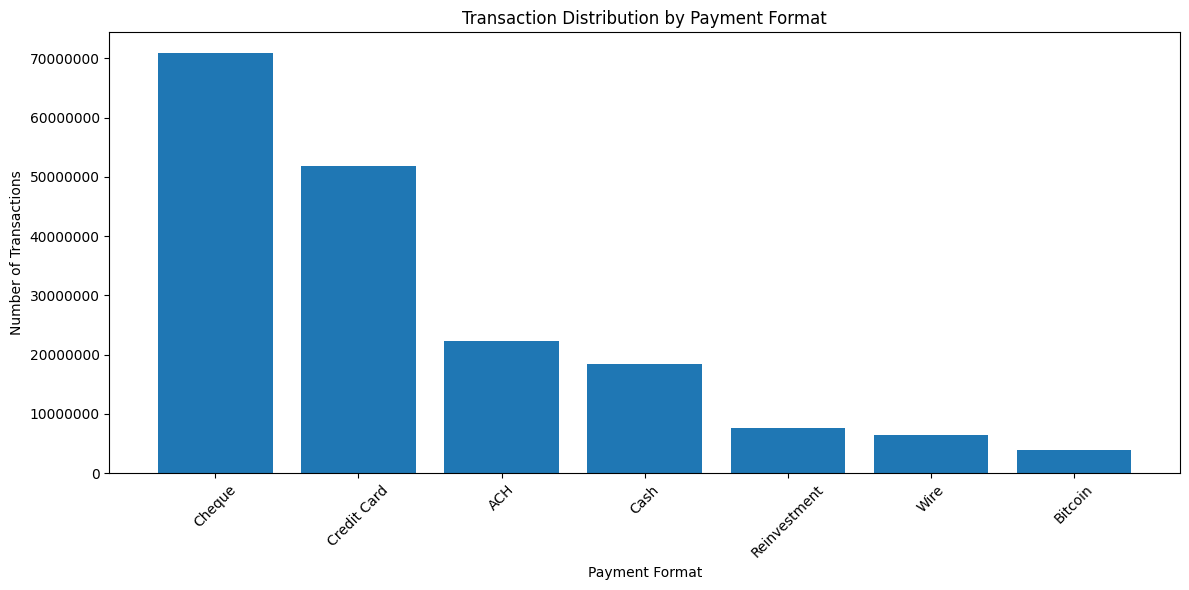

In [ ]:
#PAYMENT FORMAT DISTRIBUTION

payment_dist = (
    eda_lazy
    .group_by("Payment Format")
    .agg(
        pl.len().alias("Transaction Count")
    )
    .sort(
        "Transaction Count",
        descending=True
    )
    .collect()
)

payment_formats = payment_dist["Payment Format"].to_list()
payment_counts = payment_dist["Transaction Count"].to_list()

plt.figure(figsize=(12, 6))

plt.bar(
    payment_formats,
    payment_counts
)

plt.title("Transaction Distribution by Payment Format")
plt.xlabel("Payment Format")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)

plt.ticklabel_format(
    axis="y",
    style="plain"
)

plt.tight_layout()
plt.show()

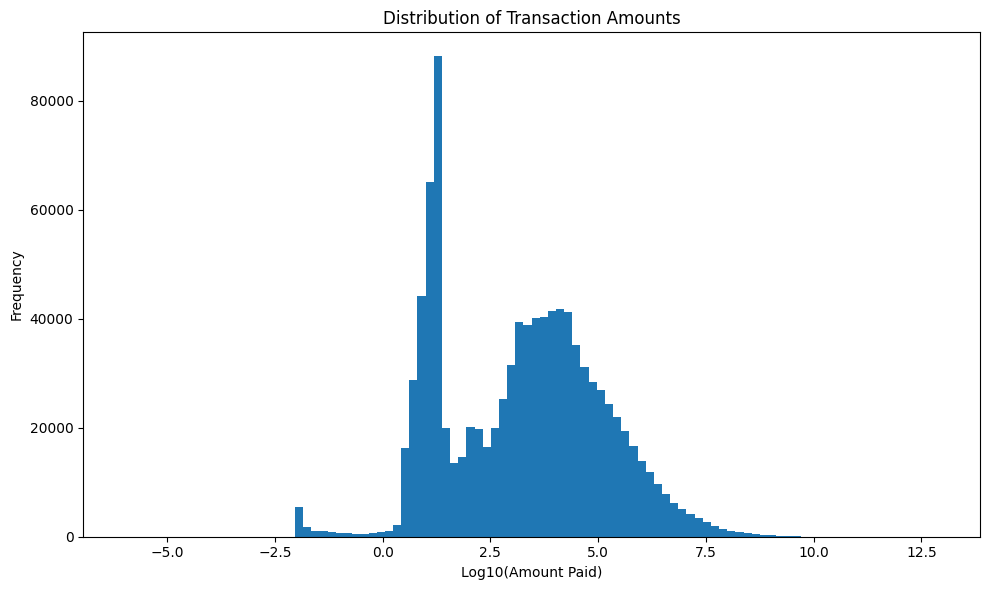

In [ ]:
#TRANSACTION AMOUNT DISTRIBUTION
amount_sample = (
    eda_lazy
    .select("Amount Paid")
    .filter(
        pl.col("Amount Paid") > 0
    )
    .head(1_000_000)
    .collect()
)

amounts = amount_sample["Amount Paid"].to_numpy()

# Log transformation because transaction amounts
# can have extreme values.
log_amounts = np.log10(amounts)

plt.figure(figsize=(10, 6))

plt.hist(
    log_amounts,
    bins=100
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Log10(Amount Paid)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

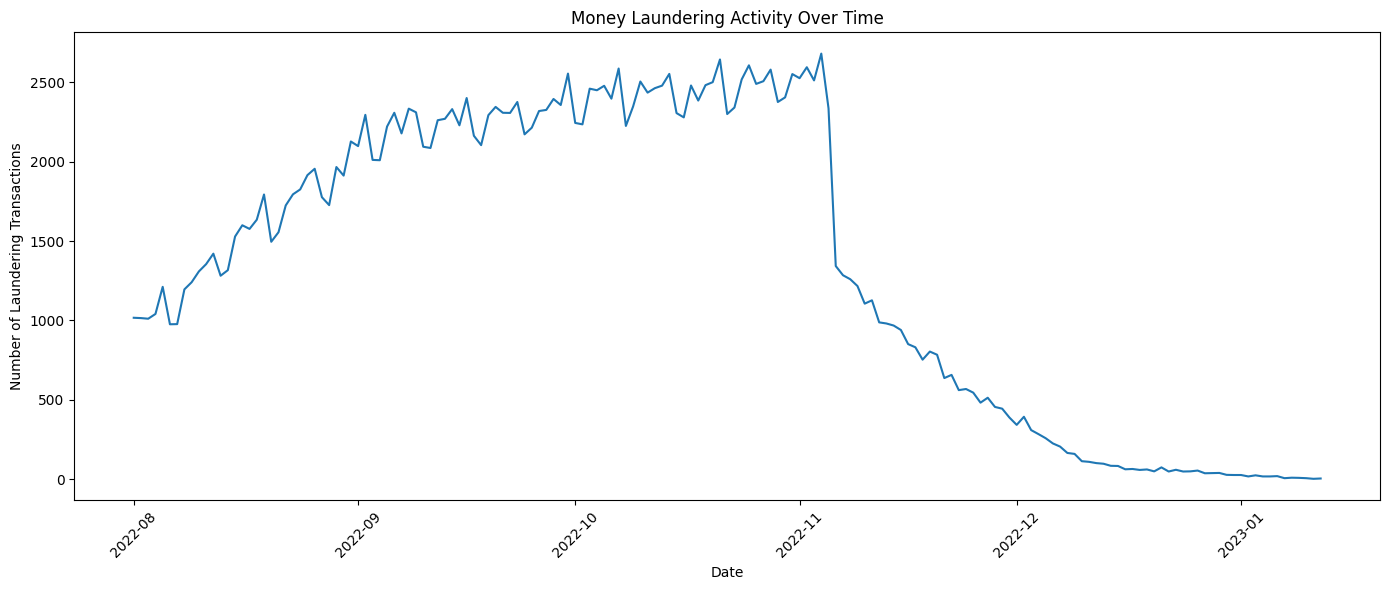

In [ ]:
# ============================================================
# GRAPH 8: LAUNDERING ACTIVITY OVER TIME
# ============================================================

laundering_time = (
    eda_lazy
    .filter(
        pl.col("Is Laundering") == 1
    )
    .with_columns(
        pl.col("Timestamp")
        .dt.date()
        .alias("Date")
    )
    .group_by("Date")
    .agg(
        pl.len().alias("Laundering Transactions")
    )
    .sort("Date")
    .collect()
)

dates = laundering_time["Date"].to_list()

laundering_counts = (
    laundering_time["Laundering Transactions"]
    .to_list()
)

plt.figure(figsize=(14, 6))

plt.plot(
    dates,
    laundering_counts
)

plt.title("Money Laundering Activity Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Laundering Transactions")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

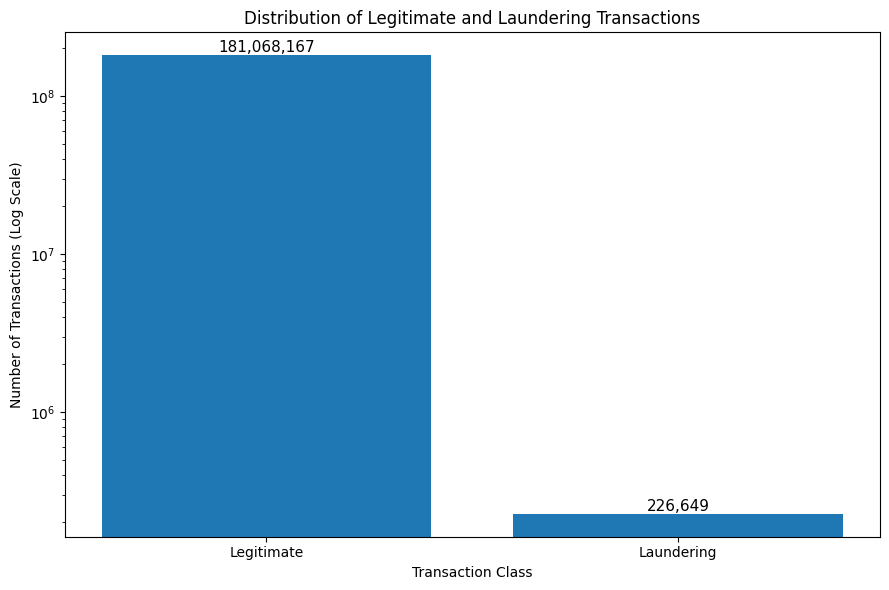

In [ ]:
#TRANSACTION CLASS DISTRIBUTION
# Calculate the number of transactions in each class
class_dist = (
    eda_lazy
    .group_by("Is Laundering")
    .agg(
        pl.len().alias("Transaction Count")
    )
    .sort("Is Laundering")
    .collect()
)

# Labels and values
labels = ["Legitimate", "Laundering"]
counts = class_dist["Transaction Count"].to_list()

# Create the graph
plt.figure(figsize=(9, 6))

plt.bar(
    labels,
    counts
)

# Use logarithmic scale because of extreme class imbalance
plt.yscale("log")

plt.title("Distribution of Legitimate and Laundering Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions (Log Scale)")

# Add the actual values above the bars
for i, count in enumerate(counts):
    plt.text(
        i,
        count,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()

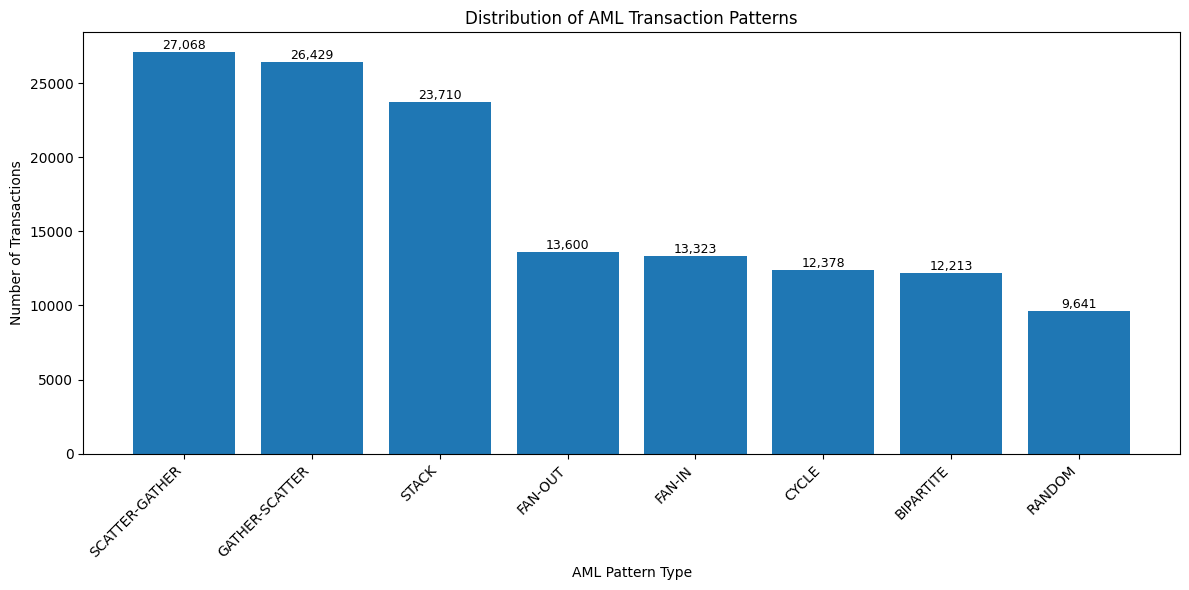

In [ ]:

#AML PATTERN DISTRIBUTION
# Count transactions for each AML pattern type
pattern_dist = (
    eda_lazy
    .filter(
        pl.col("Pattern Type").is_not_null() &
        (pl.col("Pattern Type") != "NO_PATTERN")
    )
    .group_by("Pattern Type")
    .agg(
        pl.len().alias("Transaction Count")
    )
    .sort(
        "Transaction Count",
        descending=True
    )
    .collect()
)

# Convert data to lists for visualization
patterns = pattern_dist["Pattern Type"].to_list()
counts = pattern_dist["Transaction Count"].to_list()


# Create the graph
plt.figure(figsize=(12, 6))

plt.bar(
    patterns,
    counts
)

plt.title("Distribution of AML Transaction Patterns")
plt.xlabel("AML Pattern Type")
plt.ylabel("Number of Transactions")

# Rotate pattern names for readability
plt.xticks(rotation=45, ha="right")

# Display actual counts above each bar
for i, count in enumerate(counts):
    plt.text(
        i,
        count,
        f"{count:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

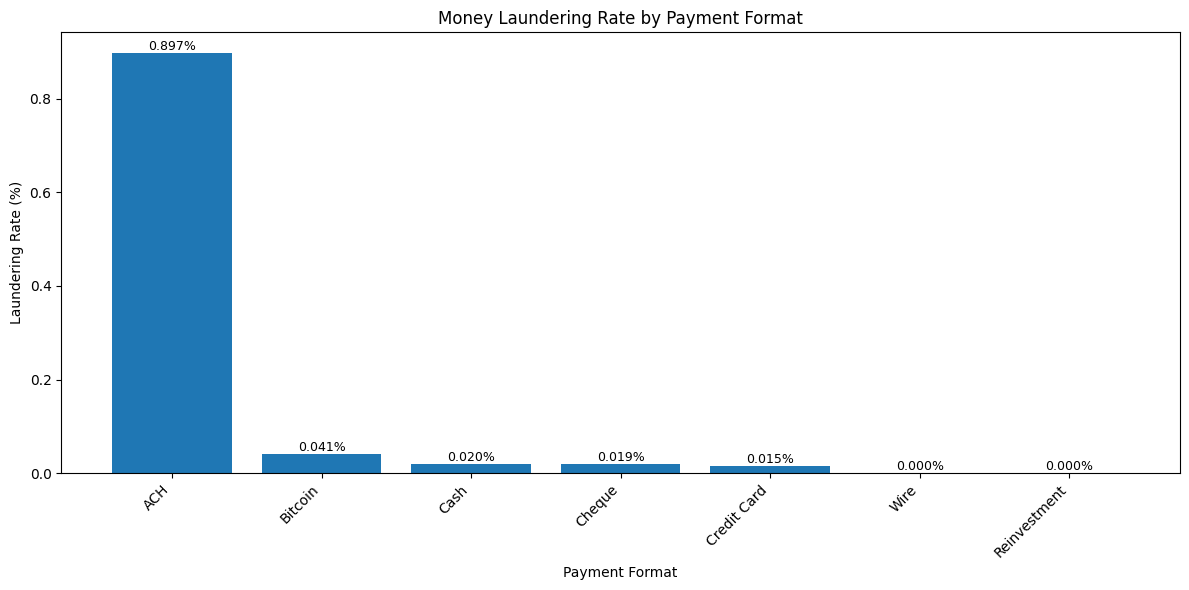

In [ ]:
#LAUNDERING RATE BY PAYMENT FORMAT
# Calculate total and laundering transactions for each payment format
laundering_payment = (
    eda_lazy
    .group_by("Payment Format")
    .agg([
        pl.len().alias("Total Transactions"),

        pl.col("Is Laundering")
        .sum()
        .alias("Laundering Transactions")
    ])
    .with_columns(
        (
            pl.col("Laundering Transactions")
            / pl.col("Total Transactions")
            * 100
        )
        .alias("Laundering Rate (%)")
    )
    .sort(
        "Laundering Rate (%)",
        descending=True
    )
    .collect()
)

# Convert to lists for visualization
payment_formats = laundering_payment["Payment Format"].to_list()

laundering_rates = (
    laundering_payment["Laundering Rate (%)"]
    .to_list()
)


# Create the graph
plt.figure(figsize=(12, 6))

plt.bar(
    payment_formats,
    laundering_rates
)

plt.title("Money Laundering Rate by Payment Format")
plt.xlabel("Payment Format")
plt.ylabel("Laundering Rate (%)")

plt.xticks(rotation=45, ha="right")


# Add percentage above each bar
for i, rate in enumerate(laundering_rates):
    plt.text(
        i,
        rate,
        f"{rate:.3f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

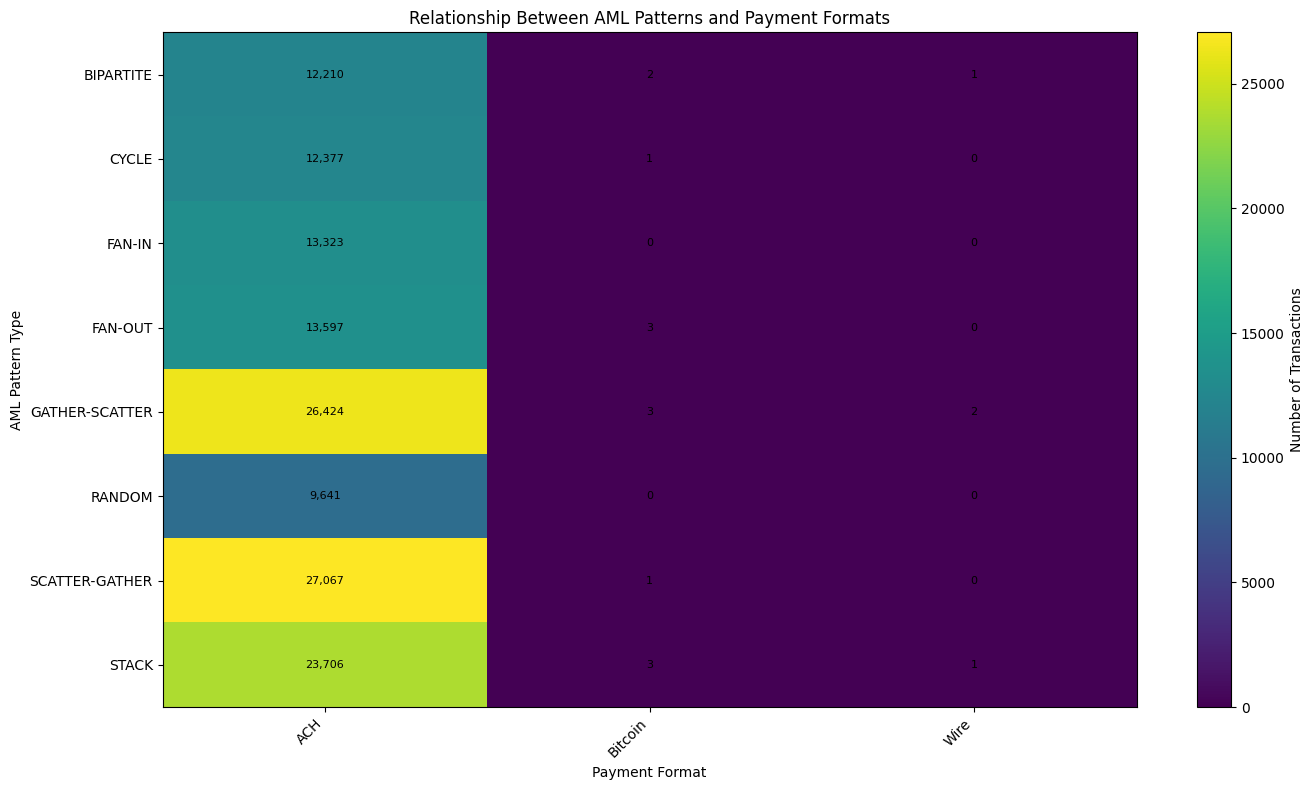

In [ ]:
# Count transactions for each Pattern Type and Payment Format
heatmap_data = (
    eda_lazy
    .filter(
        pl.col("Pattern Type").is_not_null() &
        (pl.col("Pattern Type") != "NO_PATTERN")
    )
    .group_by([
        "Pattern Type",
        "Payment Format"
    ])
    .agg(
        pl.len().alias("Transaction Count")
    )
    .collect()
)

# Convert the aggregated Polars DataFrame to Pandas
heatmap_df = heatmap_data.to_pandas()

# Create a matrix:
# Rows    = AML Pattern Types
# Columns = Payment Formats
# Values  = Number of Transactions
heatmap_matrix = heatmap_df.pivot(
    index="Pattern Type",
    columns="Payment Format",
    values="Transaction Count"
).fillna(0)

# CREATE THE HEATMAP

plt.figure(figsize=(14, 8))

plt.imshow(
    heatmap_matrix.values,
    aspect="auto"
)

plt.colorbar(
    label="Number of Transactions"
)

# Labels
plt.xticks(
    np.arange(len(heatmap_matrix.columns)),
    heatmap_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(len(heatmap_matrix.index)),
    heatmap_matrix.index
)

plt.title("Relationship Between AML Patterns and Payment Formats")
plt.xlabel("Payment Format")
plt.ylabel("AML Pattern Type")

# Display values inside cells
for i in range(len(heatmap_matrix.index)):
    for j in range(len(heatmap_matrix.columns)):

        value = int(heatmap_matrix.iloc[i, j])

        plt.text(
            j,
            i,
            f"{value:,}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

/tmp/ipykernel_523/2605228799.py:110: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


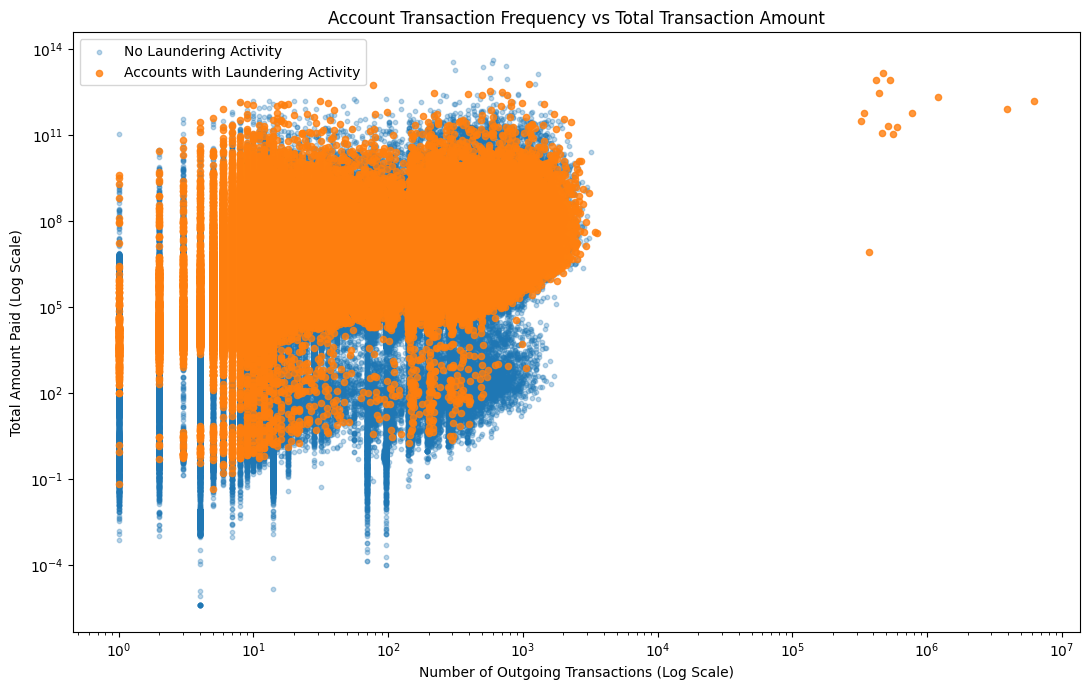

In [ ]:
#SCATTER PLOT: ACCOUNT TRANSACTION FREQUENCY
# 1. Aggregate transaction behavior for each account
account_analysis = (
    eda_lazy
    .filter(
        pl.col("Account").is_not_null() &
        (pl.col("Amount Paid") > 0)
    )
    .group_by("Account")
    .agg([
        # Number of outgoing transactions
        pl.len().alias("Transaction Frequency"),

        # Total amount sent by the account
        pl.col("Amount Paid")
        .sum()
        .alias("Total Amount Paid"),

        # Number of laundering transactions
        pl.col("Is Laundering")
        .sum()
        .alias("Laundering Transactions")
    ])
    .collect()
)
# 2. Convert columns to NumPy arrays

transaction_frequency = (
    account_analysis["Transaction Frequency"]
    .cast(pl.Float64)
    .to_numpy()
)

total_amount = (
    account_analysis["Total Amount Paid"]
    .cast(pl.Float64)
    .to_numpy()
)

laundering_transactions = (
    account_analysis["Laundering Transactions"]
    .cast(pl.Int64)
    .to_numpy()
)
# Accounts with no laundering transactions
legitimate_mask = laundering_transactions == 0

# Accounts with at least one laundering transaction
suspicious_mask = laundering_transactions > 0

# 4. Create the Scatter Plot

plt.figure(figsize=(11, 7))


# Legitimate accounts
plt.scatter(
    transaction_frequency[legitimate_mask],
    total_amount[legitimate_mask],
    alpha=0.3,
    s=10,
    label="No Laundering Activity"
)


# Accounts involved in laundering
plt.scatter(
    transaction_frequency[suspicious_mask],
    total_amount[suspicious_mask],
    alpha=0.8,
    s=20,
    label="Accounts with Laundering Activity"
)

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Account Transaction Frequency vs Total Transaction Amount"
)

plt.xlabel("Number of Outgoing Transactions (Log Scale)")
plt.ylabel("Total Amount Paid (Log Scale)")

plt.legend()

plt.tight_layout()
plt.show()